In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
url = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"

df = pd.read_csv(url)

print(df.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Information:")
print(df.describe())

Dataset Shape:
(303, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB
None

Statistical Information:
              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.0

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
print("Duplicate Values:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates Removed Successfully!")

Duplicate Values:
1
Duplicates Removed Successfully!


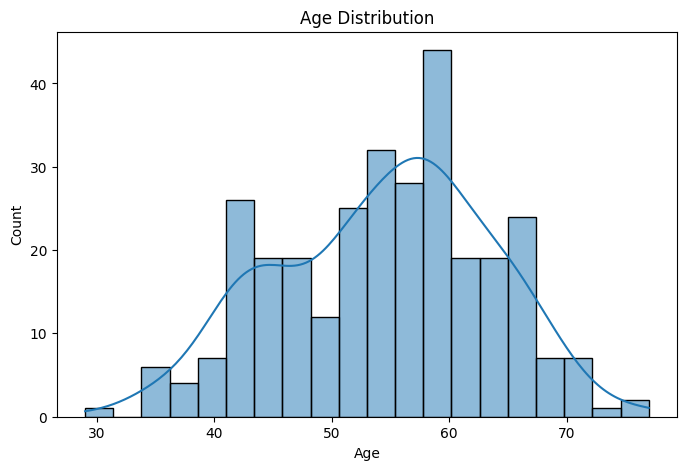

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

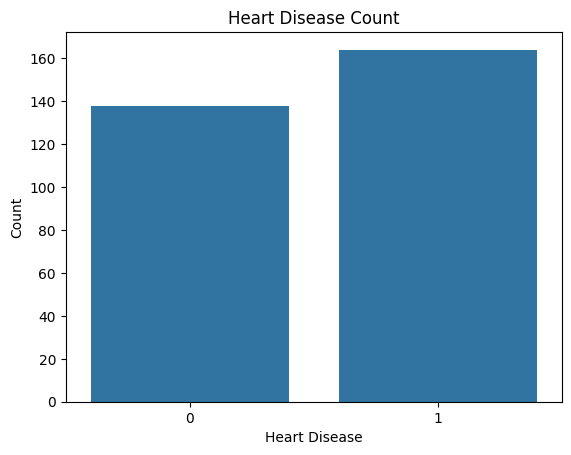

In [ ]:
sns.countplot(x='target', data=df)

plt.title("Heart Disease Count")
plt.xlabel("Heart Disease")
plt.ylabel("Count")

plt.show()

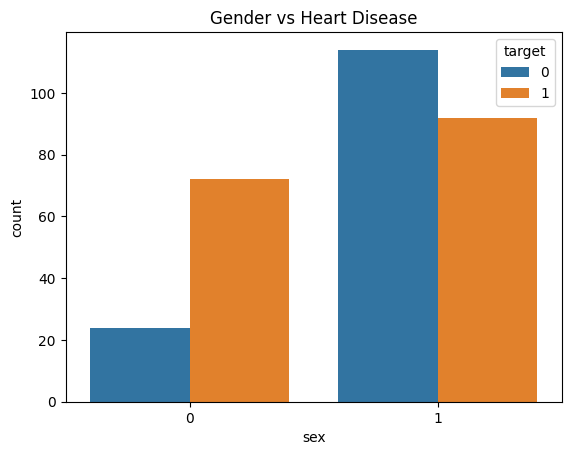

In [ ]:
sns.countplot(x='sex', hue='target', data=df)

plt.title("Gender vs Heart Disease")

plt.show()

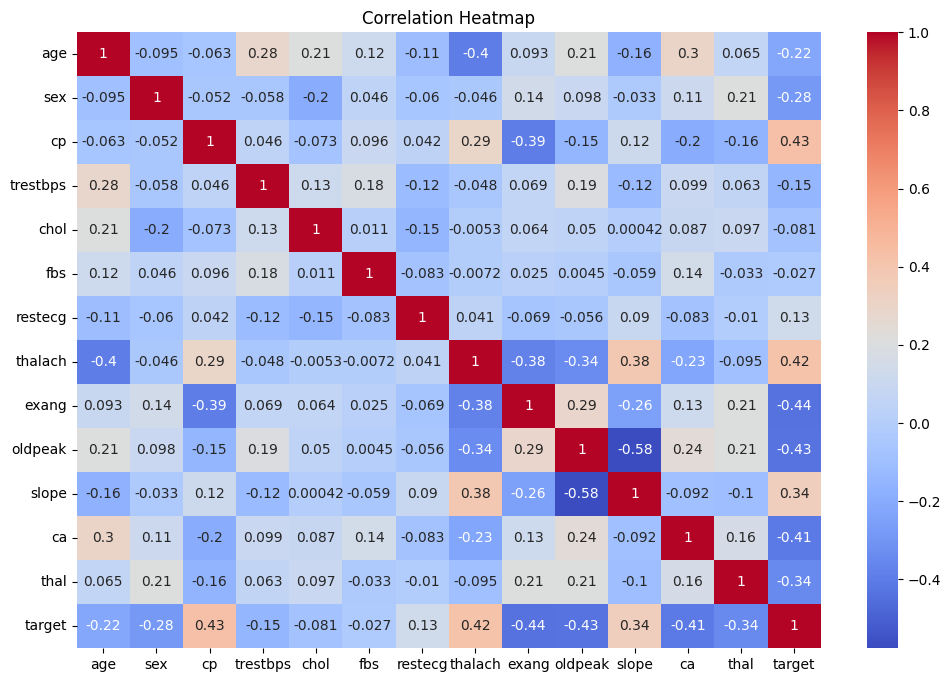

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
X = df.drop('target', axis=1)

y = df['target']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  
0   0     1  
1   0     2  
2   0     2  
3   0     2  
4   0     2  

Target Values:
0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (241, 13)
Testing Data: (61, 13)


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [ ]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Logistic Regression Completed!")

Logistic Regression Completed!


In [ ]:
dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree Completed!")

Decision Tree Completed!


In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Completed!")

Random Forest Completed!


In [ ]:
lr_acc = accuracy_score(y_test, y_pred_lr)

dt_acc = accuracy_score(y_test, y_pred_dt)

rf_acc = accuracy_score(y_test, y_pred_rf)

print("Logistic Regression Accuracy:", lr_acc * 100)

print("Decision Tree Accuracy:", dt_acc * 100)

print("Random Forest Accuracy:", rf_acc * 100)

Logistic Regression Accuracy: 78.68852459016394
Decision Tree Accuracy: 81.9672131147541
Random Forest Accuracy: 78.68852459016394


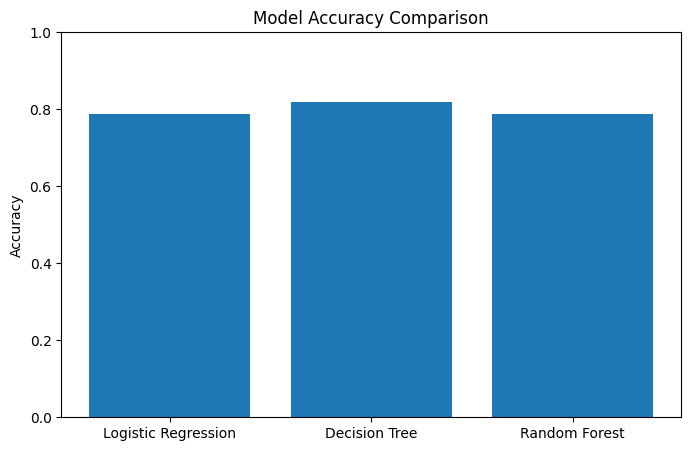

In [ ]:
models = ['Logistic Regression',
          'Decision Tree',
          'Random Forest']

accuracy = [lr_acc, dt_acc, rf_acc]

plt.figure(figsize=(8,5))

plt.bar(models, accuracy)

plt.title("Model Accuracy Comparison")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.show()

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.64      0.73        28
           1       0.75      0.91      0.82        33

    accuracy                           0.79        61
   macro avg       0.80      0.78      0.78        61
weighted avg       0.80      0.79      0.78        61



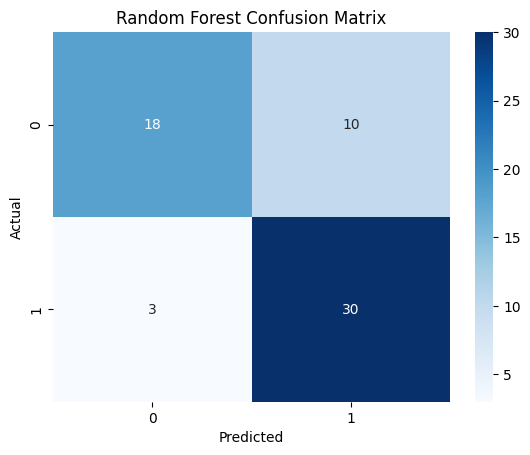

In [ ]:
print("Classification Report:")

print(classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [ ]:
print("HEART DISEASE PREDICTION SYSTEM")

age = float(input("Enter Age: "))
sex = float(input("Enter Sex (0 or 1): "))
cp = float(input("Enter Chest Pain Type: "))
trestbps = float(input("Enter Blood Pressure: "))
chol = float(input("Enter Cholesterol: "))
fbs = float(input("Enter Fasting Blood Sugar (0 or 1): "))
restecg = float(input("Enter Rest ECG: "))
thalach = float(input("Enter Maximum Heart Rate: "))
exang = float(input("Enter Exercise Angina (0 or 1): "))
oldpeak = float(input("Enter Oldpeak: "))
slope = float(input("Enter Slope: "))
ca = float(input("Enter Number of Major Vessels: "))
thal = float(input("Enter Thal: "))

patient = np.array([[
    age, sex, cp, trestbps, chol,
    fbs, restecg, thalach, exang,
    oldpeak, slope, ca, thal
]])

patient_scaled = scaler.transform(patient)

prediction = rf.predict(patient_scaled)

if prediction[0] == 1:
    print("Heart Disease Risk Detected")
else:
    print("No Heart Disease Risk Detected")

HEART DISEASE PREDICTION SYSTEM
Enter Age: 45
Enter Sex (0 or 1): 1
Enter Chest Pain Type: 2
Enter Blood Pressure: 130
Enter Cholesterol: 240
Enter Fasting Blood Sugar (0 or 1): 0
Enter Rest ECG: 1
Enter Maximum Heart Rate: 150
Enter Exercise Angina (0 or 1): 0
Enter Oldpeak: 1.0
Enter Slope: 2
Enter Number of Major Vessels: 0
Enter Thal: 2
Heart Disease Risk Detected


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


CONCLUSION

The Heart Disease Prediction project is developed using Machine Learning techniques and Python programming.

The main objective of this project is to predict the possibility of heart disease based on different patient health attributes.

In this project, we used three Machine Learning algorithms:

1. Logistic Regression
2. Decision Tree
3. Random Forest

We performed data preprocessing, data visualization, feature selection, model training and model evaluation.

We also used Accuracy, Precision, Recall, F1-score and Confusion Matrix to evaluate the performance of the models.

The system takes patient health information as input and provides a prediction as output.

Through this project, we learned how Machine Learning can be applied to healthcare-related data.

Finally, this project is an educational prototype and its predictions cannot replace professional medical diagnosis.

REFERENCES

1. Python Official Documentation – https://docs.python.org/

2. Pandas Documentation – https://pandas.pydata.org/docs/

3. NumPy Documentation – https://numpy.org/doc/

4. Matplotlib Documentation – https://matplotlib.org/stable/

5. Seaborn Documentation – https://seaborn.pydata.org/

6. Scikit-learn Documentation – https://scikit-learn.org/stable/

7. Heart Disease Dataset – UCI Machine Learning Repository.